# 21 — Constant world and local risk prices across countries

Fit **Poland, Czechia, Romania, Sweden and Hungary**, separately for **USD and EUR investors**, on
the same frozen **October 2014–September 2026** sample: **144 months** in every fit. Hungary is
**re-estimated on this common window**, rather than compared with its 321-month results.

Match notebook 03's initial benchmark: three equity portfolios, constant world/local prices,
zero pricing-error intercepts and **scalar BEKK(1,1)** conditional covariance. Compare world-only
with world-plus-local restrictions, giving **20 joint fits**. Explicit currency pricing comes later;
the unhedged equity returns already contain FX movements. This is an initial pricing benchmark,
not the final five-factor FX model or evidence about hedging costs.

Use the existing **Miniconda base** kernel. Read frozen inputs only; no fetching or installation.
The reusable engine is `regional_pricing_baseline.py`; its pricing/filter functions are unchanged
from notebook 03. Other research notebooks, engines, snapshots and outputs remain unchanged.

In [1]:
# Diagnostic/optimizer controls; all estimations use the fixed common sample.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70), (0.02, 0.96)]
MAX_ITER = 1200
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)  # 0: original notebook-03 robust QML; others: fixed sensitivities.
REUSE_FITS = True         # Revalidate cached fits; False forces estimation from all starts.
MODEL_VERSION = "regional_scalar_bekk_constant_v1"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 02 and 20 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import regional_pricing_baseline as engine
importlib.reload(engine)  # Reruns always use the engine currently on disk.

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
COUNTRY_ORDER = ["HU", "PL", "CZ", "RO", "SE"]
CURRENCIES = ["USD", "EUR"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
OUT = ROOT / "output" / "21_regional_pricing_baseline" / "2014-10_2026-09"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_sha = sha(Path(engine.__file__).read_bytes())
assert 2 <= TEST_LAGS <= 24 and HAC_LAGS[0] == 0 and all(0 <= h <= 24 for h in HAC_LAGS)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
print("Engine SHA-256:", engine_sha)

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Engine SHA-256: 5492ee11a0a0a7f7f671f8c2fce4c188cca2ec1698955778289ea7f27b35ad75


## 1. Verify the inputs and select the identical calendar

Verify both pinned input locks, the sealed regional manifest and every referenced frozen file,
including the original Hungarian research archive. Each model uses World, US and the national
equity **excess log returns in monthly percentage points**. The world and cash proxies retain
their original definitions; EUR cash remains the lagged Euribor proxy.

No predictor or regime flag enters a constant-price model. Czech back-calculated months lie
outside this common window. The inflation carry has no role in these equity-only likelihoods.

In [2]:
def verify_inputs():
    locks, expected = {}, {}
    for name, wanted in LOCK_HASHES.items():
        raw = (ROOT / name).read_bytes()
        if sha(raw) != wanted: raise ValueError(f"Input lock changed: {name}")
        locks[name] = json.loads(raw)
        for path, checksum in locks[name]["files"].items():
            if path in expected and expected[path] != checksum: raise ValueError(f"Conflicting lock: {path}")
            expected[path] = checksum
    for path, checksum in expected.items():
        if sha((ROOT / path).read_bytes()) != checksum: raise ValueError(f"Frozen file changed: {path}")
    regional = locks["regional_dataset_inputs.json"]
    raw = (ROOT / regional["root"] / "manifest.json").read_bytes()
    assert sha(raw) == regional["manifest_sha256"] and json.loads(raw)["sealed"]
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes = {}, {}, {}, {}
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT / regional["root"] / "common" / f"{country}_{currency}.csv"
        relative = path.relative_to(ROOT).as_posix()
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[relative]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all()
        assert d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"] - d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local"]].to_numpy() * 100
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, y.std(axis=0, ddof=1), sha(raw)
        assert (scales[key] > 0).all() and np.linalg.eigvalsh(np.cov(y, rowvar=False)).min() > 0
        np.testing.assert_array_equal(y[:, :2], samples[("HU", currency)][:, :2])
for country in COUNTRY_ORDER:
    np.testing.assert_allclose(frames[(country, "USD")].r_local - frames[(country, "EUR")].r_local,
                               frames[(country, "USD")].fx_other, atol=1e-12, rtol=0)
display(pd.DataFrame([{"country": NAMES[c], "perspective": p, "first": str(months[0]),
    "last": str(months[-1]), "months": len(y), "assets": "World, US, national equity"}
    for (c, p), y in samples.items()]))
print("Verified", len(input_hashes), "unique frozen files; all ten input systems share 144 months.")

,country,perspective,first,last,months,assets
0,Hungary,USD,2014-10,2026-09,144,"World, US, national equity"
1,Hungary,EUR,2014-10,2026-09,144,"World, US, national equity"
2,Poland,USD,2014-10,2026-09,144,"World, US, national equity"
3,Poland,EUR,2014-10,2026-09,144,"World, US, national equity"
4,Czechia,USD,2014-10,2026-09,144,"World, US, national equity"
5,Czechia,EUR,2014-10,2026-09,144,"World, US, national equity"
6,Romania,USD,2014-10,2026-09,144,"World, US, national equity"
7,Romania,EUR,2014-10,2026-09,144,"World, US, national equity"
8,Sweden,USD,2014-10,2026-09,144,"World, US, national equity"
9,Sweden,EUR,2014-10,2026-09,144,"World, US, national equity"


Verified 825 unique frozen files; all ten input systems share 144 months.


## 2. Pricing restrictions and conditional covariance

For each country, asset order is **World, US, national equity**. With excess returns in percentage
points and $H_t=\operatorname{Var}(\varepsilon_t\mid\mathcal F_{t-1})$:

\[
\boxed{\begin{aligned}
\mu_{W,t}&=\lambda_W H_{WW,t},\\
\mu_{US,t}&=\lambda_W H_{US,W,t}+\lambda_{US}H_{US,US,t},\\
\mu_{L,t}&=\lambda_W H_{L,W,t}+\lambda_LH_{L,L,t}.
\end{aligned}}
\]

All prices are constant and unrestricted in sign. **World-only** imposes
$\lambda_{US}=\lambda_L=0$ (9 parameters); **world/local** estimates all three (11 parameters).
US is a test asset with its own local price, not an extra common factor. Local risk uses own
conditional variance, not an orthogonalised residual variance. There are no alphas, AR terms or
explicit FX pricing contributions. The local coefficient can absorb omitted FX or other risks.

Use notebook 03's scalar BEKK(1,1):

\[
H_t=(1-\alpha-\beta)\Sigma+\alpha\varepsilon_{t-1}\varepsilon_{t-1}' +\beta H_{t-1},
\quad H_0=\Sigma,\quad \varepsilon_t=y_t-\mu_t.
\]

Estimate the six Cholesky coordinates of $\Sigma$ jointly with prices and dynamics. Softmax
coordinates give $\alpha,\beta>0$, $\alpha+\beta<1$. Sample standard deviations only scale the
optimizer coordinates; they do not fix a covariance target. Minimise the average Gaussian
quasi-likelihood, jointly updating the mean, innovations, covariance and analytic score.

This is the same initial restriction as [notebook 03](03_pricing_baseline.ipynb), in the paper's
GARCH-in-mean family. It is simpler than the later retained five-factor covariance models.
Prices multiply squared percentage-point covariances; their numeric values depend on return units.
Each country is a **separate joint system**, so its fitted world price may differ. No pooled common
world price, formal cross-country coefficient test or independent USD/EUR replication is implied.

In [3]:
check_rows = []
for key, y in samples.items():
    country, currency = key
    for partial in [False, True]:
        theta = engine.initial_theta(y, scales[key], partial)
        theta = theta + np.linspace(-.015, .02, len(theta))  # Also check off the initial point.
        args = (y[:40], scales[key], partial)
        analytic = engine.objective(theta, *args)[1]
        numeric = engine.numerical_gradient(lambda x: engine.objective(x, *args)[0], theta)
        np.testing.assert_allclose(analytic, numeric, rtol=2e-5, atol=2e-6)
        check_rows.append({"country": country, "perspective": currency, "partial": partial,
            "max_gradient_error": np.max(np.abs(analytic-numeric))})
    restricted = engine.initial_theta(y, scales[key], False)
    nested = np.r_[restricted[0], 0., 0., restricted[1:]]
    one = engine.filter_model(restricted, y, scales[key], False)
    two = engine.filter_model(nested, y, scales[key], True)
    np.testing.assert_allclose(one["losses"], two["losses"], atol=1e-12, rtol=0)
    assert np.linalg.eigvalsh(one["H"]).min() > 0
checks = pd.DataFrame(check_rows)
display(checks.groupby("perspective").max(numeric_only=True))
print("All 20 gradient checks, ten exact nesting identities and positive-covariance checks pass.")

,partial,max_gradient_error
perspective,,
EUR,True,9.633350e-10
USD,True,9.396078e-10


All 20 gradient checks, ten exact nesting identities and positive-covariance checks pass.


## 3. Fit both models from several starts

Use three fixed covariance-dynamics starts. The world/local model also starts at the fitted
world-only restriction. Require optimizer success, a finite likelihood and maximum absolute
average-score gradient below $10^{-4}$. A lower nonconverged candidate stops the comparison.
Review repeated convergence; multiple starts do not prove a global optimum.

Cached fits must match the engine hash, frozen source, settings and package versions. Revalidate
their objective, gradient, parameter bounds and positive covariances before use. No old full-history
Hungarian fit is reused as a common-window estimate. Only notebook 21's new output folder is written.

In [4]:
fits, start_rows = {}, []
for key, y in samples.items():
    country, currency = key
    for model, partial in [("world_only", False), ("world_local", True)]:
        print(f"{NAMES[country]} · {currency} · {model}", flush=True)
        config = {"version": MODEL_VERSION, "engine_sha256": engine_sha, "country": country,
            "perspective": currency, "model": model, "source_sha256": source_hashes[key],
            "first": str(months[0]), "last": str(months[-1]), "start_dynamics": START_DYNAMICS,
            "max_iter": MAX_ITER, "packages": versions, "python": platform.python_version()}
        fingerprint = sha(json.dumps(config, sort_keys=True).encode() + y.tobytes())
        path = OUT / f"fit_{country}_{currency}_{model}.json"
        record = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        if record is not None and record.get("fingerprint") == fingerprint:
            theta = np.asarray(record["theta"], dtype=float)
            value, gradient = engine.objective(theta, y, scales[key], partial)
            limits = np.asarray(engine.parameter_bounds(partial))
            valid = (record.get("optimizer_success") and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
                and np.max(np.abs(gradient)) < 1e-4 and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all())
            if not valid: record = None
        else: record = None
        if record is None:
            starts = [engine.initial_theta(y, scales[key], partial, a, b) for a, b in START_DYNAMICS]
            if partial:
                restricted = fits[(*key, "world_only")]["theta"]
                starts.insert(0, np.r_[restricted[0], 0., 0., restricted[1:]])
            best, runs = engine.fit_starts(y, scales[key], partial, starts, MAX_ITER)
            record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(),
                "mean_nll": float(best.fun), "optimizer_success": bool(best.success), "starts": runs}
            temp = path.with_suffix(".tmp")
            temp.write_text(json.dumps(record, indent=2, sort_keys=True) + "\n")
            temp.replace(path)
        else: print("  verified cached fit", flush=True)
        theta = np.asarray(record["theta"])
        filtered = engine.filter_model(theta, y, scales[key], partial)
        assert np.linalg.eigvalsh(filtered["H"]).min() > 0
        if partial:
            assert filtered["losses"].sum() <= fits[(*key, "world_only")]["filter"]["losses"].sum() + 1e-5
        fits[(*key, model)] = {"theta": theta, "filter": filtered, "partial": partial,
            "y": y, "scales": scales[key], "record": record}
        start_rows.extend({"country": country, "perspective": currency, "model": model, **r} for r in record["starts"])
starts_table = pd.DataFrame(start_rows)
display(starts_table.groupby(["country", "perspective", "model"])
    .agg(starts=("start", "count"), successes=("success", "sum"), best_mean_NLL=("mean_nll", "min"),
         worst_gradient=("max_abs_gradient", "max")).round(7))

Hungary · USD · world_only


  verified cached fit


Hungary · USD · world_local


  verified cached fit


Hungary · EUR · world_only


  verified cached fit


... (31 outputs left out)

  verified cached fit


Sweden · EUR · world_local


  verified cached fit


starts  successes  best_mean_NLL  \
country perspective model                                           
CZ      EUR         world_local       4          4       6.772659   
                    world_only        3          3       6.814042   
        USD         world_local       4          4       6.920911   
                    world_only        3          3       6.960305   
HU      EUR         world_local       4          4       7.152085   
                    world_only        3          3       7.177004   
        USD         world_local       4          4       7.278031   
                    world_only        3          3       7.310886   
PL      EUR         world_local       4          4       7.011899   
                    world_only        3          3       7.031910   
        USD         world_local       4          4       7.144056   
                    world_only        3          3       7.175429   
RO      EUR         world_local       4          4       6.950182   
                    world_only        3          3       6.985658   
        USD         world_local       4          4       7.103732   
                    world_only        3          3       7.146336   
SE      EUR         world_local       4          4       6.485824   
                    world_only        3          3       6.497578   
        USD         world_local       4          4       6.566301   
                    world_only        3          3       6.595850   

                                 worst_gradient  
country perspective model                        
CZ      EUR         world_local    8.000000e-06  
                    world_only     2.700000e-06  
        USD         world_local    8.400000e-06  
                    world_only     4.000000e-06  
HU      EUR         world_local    7.400000e-06  
                    world_only     2.400000e-06  
        USD         world_local    4.000000e-06  
                    world_only     6.000000e-07  
PL      EUR         world_local    2.900000e-06  
                    world_only     2.700000e-06  
        USD         world_local    3.200000e-06  
                    world_only     3.800000e-06  
RO      EUR         world_local    8.300000e-06  
                    world_only     3.400000e-06  
        USD         world_local    1.140000e-05  
                    world_only     4.100000e-06  
SE      EUR         world_local    2.970000e-05  
                    world_only     3.600000e-06  
        USD         world_local    1.110000e-05  
                    world_only     6.500000e-06

## 4. Curvature, robust uncertainty and local-price restrictions

Let $A$ be the Hessian of average loss. With centered per-month scores, report
$A^{-1}B_h A^{-1}/T$: **lag 0** is notebook 03's robust-QML score outer product; **3, 6 and 12** are
fixed Bartlett score-HAC sensitivities. These include uncertainty in every joint parameter.
HAC changes the score covariance, not the estimated prices or the likelihood, and does not repair
an inadequate conditional mean/covariance model.

Check central-difference Hessians at two steps. Suppress standard errors/Wald p-values at parameter
bounds, nonpositive/ill-conditioned curvature, unstable Hessians or price SEs. Keep the failure reason and the affected optimizer coordinate in `parameter_bounds.csv`.
A beta-logit lower bound means the covariance lag is nearly zero, not a proven zero persistence restriction.
Numerically available inference does not establish economic identification in a 144-month sample.

Test US local and national local prices individually, and **both local prices jointly zero**.
These are asymptotic robust Wald tests; failure to reject is not proof of market integration.
Price/test p-values are exploratory and not multiplicity-adjusted. Show every fixed bandwidth.
AIC/BIC count all 9/11 parameters and compare the nested models **within each country and currency**;
their levels across different national return vectors are not a country-performance ranking.

In [5]:
fit_rows, price_rows, test_rows, inference_rows, boundary_rows = [], [], [], [], []
for (country, currency, model), fit in fits.items():
    theta, f, y, partial = fit["theta"], fit["filter"], fit["y"], fit["partial"]
    info = engine.inference(theta, y, fit["scales"], partial, f, HAC_LAGS)
    fit["inference"] = info
    labels = (["World price scaled", "US local price scaled", "National price scaled"][:3 if partial else 1]
        + ["log L11", "L21", "log L22", "L31", "L32", "log L33", "alpha logit", "beta logit"])
    limits = np.asarray(engine.parameter_bounds(partial))
    distance = np.minimum(theta-limits[:, 0], limits[:, 1]-theta)
    boundary_rows.extend({"country": country, "perspective": currency, "model": model, "parameter": label,
        "coordinate": theta[j], "lower": limits[j, 0], "upper": limits[j, 1], "distance_to_bound": distance[j],
        "near_bound": bool(distance[j] < 1e-4)} for j, label in enumerate(labels))
    loglik = -f["losses"].sum()
    fit_rows.append({"country": country, "perspective": currency, "model": model, "n": len(y),
        "parameters": len(theta), "loglik": loglik, "AIC": -2*loglik+2*len(theta),
        "BIC": -2*loglik+np.log(len(y))*len(theta), "alpha": f["alpha"], "beta": f["beta"],
        "persistence": f["alpha"]+f["beta"], "max_abs_gradient": np.abs(f["scores"].mean(axis=0)).max(),
        "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(),
        "bound_parameters": "; ".join(label for j, label in enumerate(labels) if distance[j] < 1e-4),
        **{name: info[name] for name in ["Hessian_min_eigenvalue", "Hessian_condition", "Hessian_step_difference", "min_distance_to_bounds"]}})
    for lag, estimate in info["estimates"].items():
        ready, V = estimate["ready"], estimate["covariance"]
        inference_rows.append({"country": country, "perspective": currency, "model": model, "HAC_lag": lag,
            "ready": ready, "reason": estimate["reason"], "price_SE_step_difference": estimate["price_SE_step_difference"]})
        for j, risk in enumerate(["World", "US local", "National local"][:3 if partial else 1]):
            value = f["prices"][j]
            se = engine.PRICE_SCALE*np.sqrt(V[j, j]) if ready else np.nan
            price_rows.append({"country": country, "perspective": currency, "model": model, "risk": risk,
                "HAC_lag": lag, "estimate": value, "robust_se": se,
                "p_value": 2*norm.sf(abs(value/se)) if ready else np.nan,
                "ci95_low": value-1.96*se, "ci95_high": value+1.96*se, "inference_ready": ready,
                "reason": estimate["reason"]})
        if partial:
            for restriction, ids in [("Both local prices zero", [1, 2]), ("National local price zero", [2]), ("US local price zero", [1])]:
                block, value = V[np.ix_(ids, ids)], theta[ids]
                statistic = value @ np.linalg.solve(block, value) if ready else np.nan
                test_rows.append({"country": country, "perspective": currency, "HAC_lag": lag,
                    "restriction": restriction, "Wald_statistic": statistic, "df": len(ids),
                    "p_value": chi2.sf(statistic, len(ids)) if ready else np.nan,
                    "inference_ready": ready, "reason": estimate["reason"]})
fit_table, price_table, tests, inference_audit = map(pd.DataFrame, [fit_rows, price_rows, test_rows, inference_rows])
display(fit_table.set_index(["country", "perspective", "model"])[
    ["n", "parameters", "AIC", "BIC", "persistence", "max_abs_gradient", "Hessian_condition"]].round(5))
display(price_table.query("model == 'world_local' and HAC_lag == 0").set_index(["country", "perspective", "risk"])
    [["estimate", "robust_se", "p_value", "inference_ready", "reason"]].round(5))
display(tests.query("restriction == 'Both local prices zero'").pivot(index=["country", "perspective"], columns="HAC_lag", values="p_value").round(5))
boundary_audit = pd.DataFrame(boundary_rows)
display(boundary_audit.loc[boundary_audit.near_bound].set_index(["country", "perspective", "model"]))

n  parameters         AIC         BIC  \
country perspective model                                                  
HU      USD         world_only   144           9  2123.53505  2150.26337   
                    world_local  144          11  2118.07305  2150.74100   
        EUR         world_only   144           9  2084.97726  2111.70558   
                    world_local  144          11  2081.80057  2114.46852   
PL      USD         world_only   144           9  2084.52367  2111.25199   
                    world_local  144          11  2079.48803  2112.15597   
        EUR         world_only   144           9  2043.19017  2069.91849   
                    world_local  144          11  2041.42692  2074.09487   
CZ      USD         world_only   144           9  2022.56784  2049.29616   
                    world_local  144          11  2015.22228  2047.89023   
        EUR         world_only   144           9  1980.44401  2007.17233   
                    world_local  144          11  1972.52593  2005.19388   
RO      USD         world_only   144           9  2076.14469  2102.87301   
                    world_local  144          11  2067.87479  2100.54274   
        EUR         world_only   144           9  2029.86952  2056.59784   
                    world_local  144          11  2023.65232  2056.32027   
SE      USD         world_only   144           9  1917.60486  1944.33318   
                    world_local  144          11  1913.09462  1945.76257   
        EUR         world_only   144           9  1889.30242  1916.03074   
                    world_local  144          11  1889.91716  1922.58511   

                                 persistence  max_abs_gradient  \
country perspective model                                        
HU      USD         world_only       0.59255           0.00000   
                    world_local      0.56077           0.00000   
        EUR         world_only       0.10883           0.00000   
                    world_local      0.16770           0.00000   
PL      USD         world_only       0.17667           0.00000   
                    world_local      0.19975           0.00000   
        EUR         world_only       0.18874           0.00000   
                    world_local      0.20247           0.00000   
CZ      USD         world_only       0.69376           0.00000   
                    world_local      0.34764           0.00000   
        EUR         world_only       0.21057           0.00000   
                    world_local      0.12090           0.00001   
RO      USD         world_only       0.44035           0.00000   
                    world_local      0.32178           0.00000   
        EUR         world_only       0.22173           0.00000   
                    world_local      0.19356           0.00000   
SE      USD         world_only       0.74396           0.00000   
                    world_local      0.20052           0.00000   
        EUR         world_only       0.72291           0.00000   
                    world_local      0.66669           0.00000   

                                 Hessian_condition  
country perspective model                           
HU      USD         world_only        2.287115e+04  
                    world_local       2.430973e+04  
        EUR         world_only        8.445293e+08  
                    world_local       2.531024e+05  
PL      USD         world_only        1.331459e+05  
                    world_local       1.030714e+05  
        EUR         world_only        3.349661e+07  
                    world_local       3.777092e+07  
CZ      USD         world_only        2.646110e+04  
                    world_local       3.581012e+04  
        EUR         world_only        7.378978e+04  
                    world_local       5.429316e+08  
RO      USD         world_only        2.509501e+04  
                    world_local       2.891839e+04  
        EUR         world_only        3.174624e+04  
        

estimate  robust_se  p_value  \
country perspective risk                                           
HU      USD         World            0.05638    0.02740  0.03962   
                    US local         0.01187    0.00550  0.03080   
                    National local   0.00668    0.01063  0.52974   
        EUR         World            0.07925    0.03103  0.01064   
                    US local         0.00942    0.00533  0.07744   
                    National local   0.01252    0.01621  0.43971   
PL      USD         World            0.05988    0.03021  0.04743   
                    US local         0.01438    0.00600  0.01663   
                    National local  -0.00935    0.00937  0.31840   
        EUR         World            0.08318        NaN      NaN   
                    US local         0.00999        NaN      NaN   
                    National local  -0.00062        NaN      NaN   
CZ      USD         World            0.06167    0.03181  0.05254   
                    US local         0.01352    0.00587  0.02137   
                    National local   0.00450    0.01364  0.74178   
        EUR         World            0.08228        NaN      NaN   
                    US local         0.01003        NaN      NaN   
                    National local   0.02236        NaN      NaN   
RO      USD         World            0.05190    0.02693  0.05393   
                    US local         0.01256    0.00559  0.02454   
                    National local   0.01394    0.01575  0.37604   
        EUR         World            0.07513    0.02880  0.00909   
                    US local         0.00936    0.00501  0.06157   
                    National local   0.02717    0.02092  0.19399   
SE      USD         World            0.05937    0.03206  0.06401   
                    US local         0.01568    0.00617  0.01105   
                    National local  -0.01215    0.00678  0.07309   
        EUR         World            0.08587    0.03020  0.00446   
                    US local         0.00859    0.00614  0.16155   
                    National local  -0.00943    0.00945  0.31860   

                                    inference_ready             reason  
country perspective risk                                                
HU      USD         World                      True  numerically ready  
                    US local                   True  numerically ready  
                    National local             True  numerically ready  
        EUR         World                      True  numerically ready  
                    US local                   True  numerically ready  
                    National local             True  numerically ready  
PL      USD         World                      True  numerically ready  
                    US local                   True  numerically ready  
                    National local             True  numerically ready  
        EUR         World                     False    parameter bound  
                    US local                  False    parameter bound  
                    National local            False    parameter bound  
CZ      USD         World                      True  numerically ready  
                    US local                   True  numerically ready  
                    National local             True  numerically ready  
        EUR         World                     False    parameter bound  
                    US local                  False    parameter bound  
                    National local            False    parameter bound  
RO      USD         World                      True  numerically ready  
                    US local                   True  numerically ready  
                    National local             True  numerically ready  
        EUR         World                      True  numerically ready  
                    US local                   True  numerically ready  
                    National local

HAC_lag                   0        3        6        12
country perspective                                    
CZ      EUR              NaN      NaN      NaN      NaN
        USD          0.01702  0.01382  0.00813  0.00273
HU      EUR          0.04266  0.05378  0.04933  0.04553
        USD          0.02864  0.02762  0.02345  0.02185
PL      EUR              NaN      NaN      NaN      NaN
        USD          0.05664  0.05265  0.03925  0.02613
RO      EUR          0.03007  0.03703  0.01534  0.00168
        USD          0.01320  0.01733  0.00891  0.00183
SE      EUR          0.32058  0.38576  0.31126  0.23455
        USD          0.03104  0.02765  0.00640  0.00174

parameter  coordinate  lower  upper  \
country perspective model                                               
HU      EUR         world_only   beta logit       -10.0  -10.0   10.0   
PL      EUR         world_only   beta logit       -10.0  -10.0   10.0   
                    world_local  beta logit       -10.0  -10.0   10.0   
CZ      EUR         world_local  beta logit       -10.0  -10.0   10.0   

                                 distance_to_bound  near_bound  
country perspective model                                       
HU      EUR         world_only                 0.0        True  
PL      EUR         world_only                 0.0        True  
                    world_local                0.0        True  
CZ      EUR         world_local                0.0        True

## 5. Residual adequacy

For each fitted asset, inspect marginal standardised innovations, Ljung–Box on innovations and
centered squared innovations, and ARCH LM. Inspect Cholesky-whitened cross-products as a screen
of remaining cross-covariance dynamics. Report raw and Holm-adjusted p-values, adjusting separately
within model × investor currency × diagnostic type across the five fitted systems (15 asset/pair
series). The shared raw world return has different fitted innovations in each joint system.

These are approximate residual screens with **no full estimated-GARCH degrees-of-freedom correction**,
not formal specification acceptance tests. Rejections flag work for the next covariance/FX stage;
non-rejection in 144 observations is not model validation. USD/EUR tests are dependent.

In [6]:
residual_rows, cross_rows = [], []
for (country, currency, model), fit in fits.items():
    f = fit["filter"]
    z = f["errors"] / np.sqrt(np.diagonal(f["H"], axis1=1, axis2=2))
    white = np.linalg.solve(np.linalg.cholesky(f["H"]), f["errors"][..., None])[..., 0]
    for j, asset in enumerate(["World", "US", "National"]):
        lb = lambda s: acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True).lb_pvalue.iloc[0]
        residual_rows.append({"country": country, "perspective": currency, "model": model, "asset": asset,
            "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1), "LB_z_p": lb(z[:, j]),
            "LB_z_squared_p": lb((z[:, j]-z[:, j].mean())**2),
            "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
    for i, j in [(0, 1), (0, 2), (1, 2)]:
        product = white[:, i]*white[:, j]
        cross_rows.append({"country": country, "perspective": currency, "model": model,
            "pair": f"{['World', 'US', 'National'][i]}/{['World', 'US', 'National'][j]}",
            "mean_whitened_product": product.mean(), "LB_product_p": lb(product)})
residuals, cross = pd.DataFrame(residual_rows), pd.DataFrame(cross_rows)
for table, columns in [(residuals, ["LB_z_p", "LB_z_squared_p", "ARCH_LM_p"]), (cross, ["LB_product_p"])]:
    for _, idx in table.groupby(["model", "perspective"]).groups.items():
        for column in columns:
            table.loc[idx, column+"_holm"] = multipletests(table.loc[idx, column], method="holm")[1]
display(residuals.query("model == 'world_local' and asset == 'National'")
    .set_index(["country", "perspective"])[["z_mean", "z_sd", "LB_z_p", "LB_z_p_holm", "ARCH_LM_p", "ARCH_LM_p_holm"]].round(5))

z_mean     z_sd   LB_z_p  LB_z_p_holm  ARCH_LM_p  \
country perspective                                                      
HU      USD         -0.01922  1.00758  0.62083          1.0    0.49309   
        EUR         -0.00887  1.00588  0.49169          1.0    0.38844   
PL      USD         -0.04636  1.01237  0.44851          1.0    0.16765   
        EUR         -0.04591  1.02051  0.48654          1.0    0.23131   
CZ      USD         -0.00910  1.01148  0.80264          1.0    0.21297   
        EUR          0.00196  1.01141  0.46686          1.0    0.25688   
RO      USD          0.02213  1.00922  0.15900          1.0    0.89459   
        EUR          0.03203  1.00890  0.21915          1.0    0.97115   
SE      USD         -0.06268  1.01018  0.93016          1.0    0.70154   
        EUR         -0.07993  1.01837  0.80411          1.0    0.89038   

                     ARCH_LM_p_holm  
country perspective                  
HU      USD                     1.0  
        EUR                     1.0  
PL      USD                     1.0  
        EUR                     1.0  
CZ      USD                     1.0  
        EUR                     1.0  
RO      USD                     1.0  
        EUR                     1.0  
SE      USD                     1.0  
        EUR                     1.0

## 6. Compare fitted prices and premium contributions with Hungary

For national equity, $\lambda_WH_{L,W,t}$ is the world contribution and
$\lambda_LH_{L,L,t}$ the local contribution. They add to the fitted conditional mean; **neither is
an explicit currency premium**. Constant prices still produce changing premiums through changing
conditional covariances. The average fitted mean need not equal the realised sample mean.

Charts show world/local fits only. Error bars use primary lag-0 robust 95% intervals; points without
an interval have suppressed inference. The decomposition compares monthly percentage-point means,
with positive and negative terms drawn separately. No formal country-versus-Hungary coefficient
test is reported: the country systems share observations and are statistically dependent.

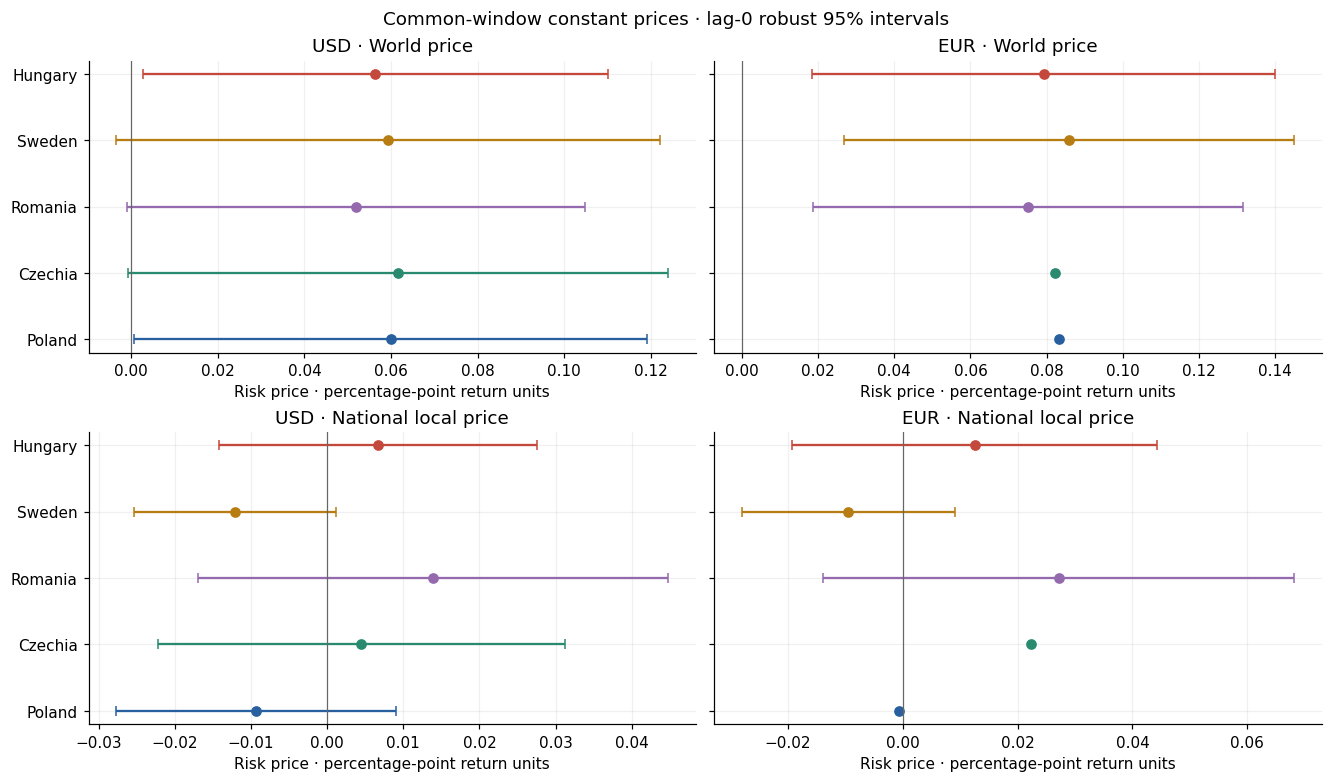

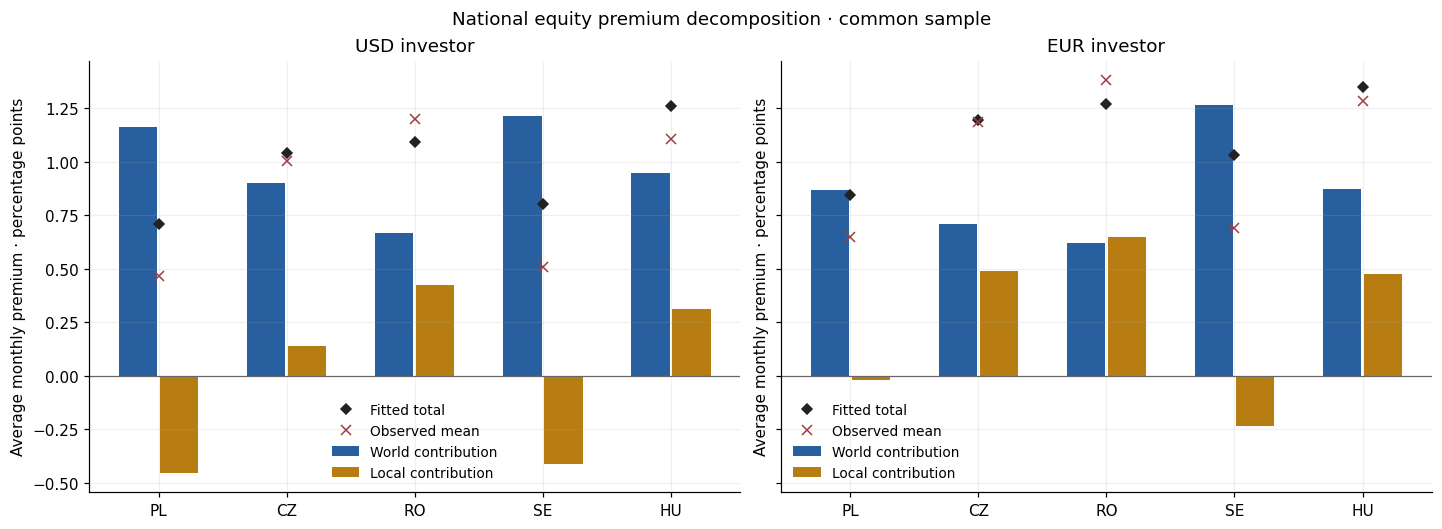

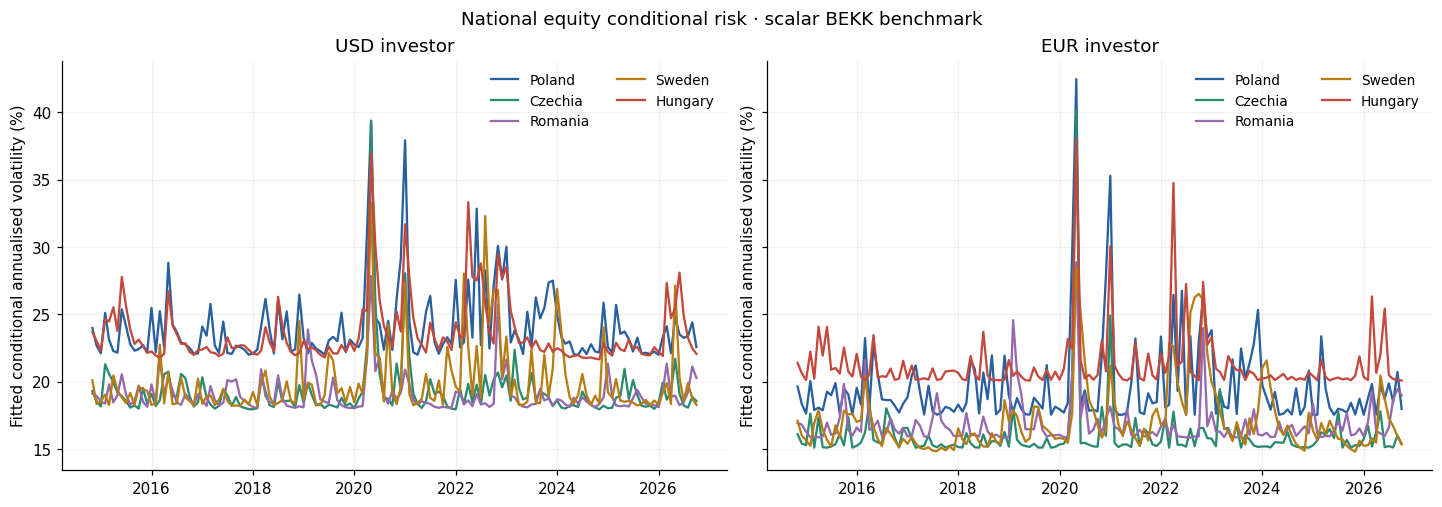

In [7]:
premium_rows, comparison_rows = [], []
for (country, currency, model), fit in fits.items():
    f = fit["filter"]
    world = f["prices"][0]*f["H"][:, 2, 0]
    local = f["prices"][2]*f["H"][:, 2, 2]
    np.testing.assert_allclose(world+local, f["mu"][:, 2], atol=1e-12, rtol=0)
    premium_rows.extend({"month": str(month), "country": country, "perspective": currency, "model": model,
        "world_price": f["prices"][0], "national_local_price": f["prices"][2],
        "world_covariance_pp2": f["H"][t, 2, 0], "own_variance_pp2": f["H"][t, 2, 2],
        "world_premium_pp": world[t], "local_premium_pp": local[t], "fitted_mean_pp": f["mu"][t, 2],
        "observed_excess_return_pp": fit["y"][t, 2]} for t, month in enumerate(months))
    if model == "world_local":
        choose = lambda restriction, lag: tests.loc[(tests.country == country) & (tests.perspective == currency)
            & (tests.restriction == restriction) & (tests.HAC_lag == lag), "p_value"].iloc[0]
        nested = fit_table.loc[(fit_table.country == country) & (fit_table.perspective == currency)].set_index("model")
        diagnostics = residuals.query("country == @country and perspective == @currency and model == 'world_local'")
        products = cross.query("country == @country and perspective == @currency and model == 'world_local'")
        comparison_rows.append({"country": country, "name": NAMES[country], "perspective": currency, "months": len(months),
            "world_price": f["prices"][0], "US_local_price": f["prices"][1], "national_local_price": f["prices"][2],
            "mean_world_premium_pp": world.mean(), "mean_local_premium_pp": local.mean(),
            "mean_fitted_premium_pp": f["mu"][:, 2].mean(), "mean_observed_excess_pp": fit["y"][:, 2].mean(),
            "delta_AIC_vs_world_only": nested.loc["world_local", "AIC"]-nested.loc["world_only", "AIC"],
            "delta_BIC_vs_world_only": nested.loc["world_local", "BIC"]-nested.loc["world_only", "BIC"],
            "local_joint_p_QML": choose("Both local prices zero", 0),
            "local_joint_p_HAC12": choose("Both local prices zero", 12),
            "national_local_p_QML": choose("National local price zero", 0),
            "US_local_p_QML": choose("US local price zero", 0),
            "numerical_inference_ready": fit["inference"]["estimates"][0]["ready"],
            "inference_reason": fit["inference"]["estimates"][0]["reason"],
            "mean_flags_holm_5pct": int(diagnostics.LB_z_p_holm.lt(.05).sum()),
            "variance_flags_holm_5pct": int((diagnostics.LB_z_squared_p_holm.lt(.05) | diagnostics.ARCH_LM_p_holm.lt(.05)).sum()),
            "cross_flags_holm_5pct": int(products.LB_product_p_holm.lt(.05).sum())})
premiums, comparison = pd.DataFrame(premium_rows), pd.DataFrame(comparison_rows)
figure_files = []
def save_plot(name):
    plt.savefig(OUT/name, dpi=170, bbox_inches="tight", metadata={"Software": "Regional pricing notebook 21"})
    figure_files.append(name)
    plt.show()
    plt.close()

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True, layout="constrained")
for col, currency in enumerate(CURRENCIES):
    for row, risk in enumerate(["World", "National local"]):
        ax = axes[row, col]
        p = price_table.query("perspective == @currency and model == 'world_local' and risk == @risk and HAC_lag == 0").set_index("country")
        for i, country in enumerate(NAMES):
            value = p.loc[country]
            ax.plot(value.estimate, i, "o", color=COLORS[country])
            if value.inference_ready: ax.errorbar(value.estimate, i, xerr=1.96*value.robust_se, color=COLORS[country], capsize=3)
        ax.axvline(0, color="#666666", lw=.8)
        ax.set(yticks=range(5), yticklabels=list(NAMES.values()), title=f"{currency} · {risk} price", xlabel="Risk price · percentage-point return units")
fig.suptitle("Common-window constant prices · lag-0 robust 95% intervals")
save_plot("01_risk_prices.png")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7), sharey=True, layout="constrained")
for ax, currency in zip(axes, CURRENCIES):
    c = comparison.query("perspective == @currency").set_index("country").loc[list(NAMES)]
    x = np.arange(5)
    ax.bar(x-.16, c.mean_world_premium_pp, width=.3, color="#285f9e", label="World contribution")
    ax.bar(x+.16, c.mean_local_premium_pp, width=.3, color="#b77d13", label="Local contribution")
    ax.plot(x, c.mean_fitted_premium_pp, "D", color="#222222", label="Fitted total", ms=5)
    ax.plot(x, c.mean_observed_excess_pp, "x", color="#a03d44", label="Observed mean", ms=7)
    ax.axhline(0, color="#666666", lw=.8)
    ax.set(xticks=x, xticklabels=list(NAMES), title=f"{currency} investor", ylabel="Average monthly premium · percentage points")
    ax.legend(frameon=False, fontsize=9)
fig.suptitle("National equity premium decomposition · common sample")
save_plot("02_mean_premiums.png")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, layout="constrained")
for ax, currency in zip(axes, CURRENCIES):
    for country in NAMES:
        f = fits[(country, currency, "world_local")]["filter"]
        ax.plot(months.to_timestamp("M"), np.sqrt(f["H"][:, 2, 2]*12), color=COLORS[country], label=NAMES[country], lw=1.5)
    ax.set(title=f"{currency} investor", ylabel="Fitted conditional annualised volatility (%)")
    ax.legend(frameon=False, ncol=2, fontsize=9)
fig.suptitle("National equity conditional risk · scalar BEKK benchmark")
save_plot("03_conditional_volatility.png")

## 7. Final common-sample comparison and saved results

Read point estimates, numerical inference status and residual adequacy together. A positive local
coefficient is conditional on this restricted equity-only model; it is not a separately identified
currency premium, a hedge cost or a causal economic drag. The country portfolios differ in sector
weights, concentration and index conventions. Later covariance/FX specifications can change results.

Keep Hungary's common-window baseline as the reference when moving through the regional pipeline.
The next step is covariance sensitivity, followed by explicit currency pricing on the same calendar.

In [8]:
display(comparison.set_index(["name", "perspective"])[["world_price", "national_local_price",
    "mean_world_premium_pp", "mean_local_premium_pp", "delta_BIC_vs_world_only",
    "national_local_p_QML", "local_joint_p_QML", "local_joint_p_HAC12", "numerical_inference_ready"]].round(5))
display(comparison.set_index(["name", "perspective"])[["inference_reason", "mean_flags_holm_5pct",
    "variance_flags_holm_5pct", "cross_flags_holm_5pct"]])
tables = {"implementation_checks.csv": checks, "starting_points.csv": starts_table,
    "fit_summary.csv": fit_table, "risk_prices.csv": price_table, "local_risk_tests.csv": tests,
    "inference_audit.csv": inference_audit, "parameter_bounds.csv": boundary_audit, "residual_diagnostics.csv": residuals,
    "cross_covariance_diagnostics.csv": cross, "premium_components.csv": premiums,
    "common_comparison.csv": comparison}
for name, table in tables.items(): table.to_csv(OUT/name, index=False, float_format="%.17g", lineterminator="\n")
parameter_files, fit_files = [], []
for (country, currency, model), fit in fits.items():
    name = f"parameters_{country}_{currency}_{model}.npz"
    f = fit["filter"]
    np.savez(OUT/name, theta=fit["theta"], H=f["H"], mu=f["mu"], errors=f["errors"],
        scores=f["scores"], target=f["target"], Hessian=fit["inference"]["Hessian"],
        **{f"covariance_HAC{lag}": estimate["covariance"] for lag, estimate in fit["inference"]["estimates"].items()})
    parameter_files.append(name)
    fit_files.append(f"fit_{country}_{currency}_{model}.json")
_, after_hashes = verify_inputs()
assert input_hashes == after_hashes and sha(Path(engine.__file__).read_bytes()) == engine_sha
outputs = [*tables, *figure_files, *parameter_files, *fit_files]
metadata = {"notebook": "21_regional_pricing_baseline.ipynb", "model_version": MODEL_VERSION,
    "engine": "regional_pricing_baseline.py", "engine_sha256": engine_sha,
    "first": str(months[0]), "last": str(months[-1]), "observations_per_fit": len(months), "fits": len(fits),
    "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes,
    "settings": {"START_DYNAMICS": START_DYNAMICS, "MAX_ITER": MAX_ITER, "TEST_LAGS": TEST_LAGS, "HAC_LAGS": HAC_LAGS},
    "python": sys.executable, "python_version": platform.python_version(), "packages": versions,
    "outputs": {name: sha((OUT/name).read_bytes()) for name in outputs},
    "notes": ["Same 144 frozen months for every country including re-estimated Hungary",
        "Three equities; scalar BEKK; constant world and local risk prices; no FX pricing; zero alphas",
        "Separate country joint systems; no cross-country coefficient significance tests",
        "Primary score-OPG QML, fixed score-HAC 3/6/12 sensitivities; invalid inference suppressed"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True) + "\n")
unready = int((~comparison.numerical_inference_ready).sum())
valid = comparison.loc[comparison.numerical_inference_ready]
display(Markdown(f"**Primary tests:** among {len(valid)} numerically ready world/local systems, "
    f"{int(valid.local_joint_p_QML.lt(.05).sum())} reject both local prices jointly zero, while "
    f"{int(valid.national_local_p_QML.lt(.05).sum())} reject the national local price individually at an unadjusted 5%. "
    "The joint rejection can be driven by the US local term; it does not establish that the national local term is priced. "
    "The other systems have unavailable inference, rather than non-rejections. Check all fixed HAC results as well."))
display(Markdown(f"**Completed:** {len(fits)} joint fits on **{months[0]}–{months[-1]}**, "
    f"{len(months)} months each, in base. **{unready}** world/local systems have suppressed primary numerical inference. "
    f"Saved {len(tables)} tables, {len(figure_files)} charts and full parameter/covariance arrays in `{OUT.relative_to(ROOT)}`. "
    "All frozen inputs and earlier research outputs are unchanged. Inspect inference/residual flags before interpreting risk prices."))

world_price  national_local_price  mean_world_premium_pp  \
name    perspective                                                             
Hungary USD              0.05638               0.00668                0.94741   
        EUR              0.07925               0.01252                0.87186   
Poland  USD              0.05988              -0.00935                1.16110   
        EUR              0.08318              -0.00062                0.86570   
Czechia USD              0.06167               0.00450                0.89883   
        EUR              0.08228               0.02236                0.70814   
Romania USD              0.05190               0.01394                0.66889   
        EUR              0.07513               0.02717                0.62140   
Sweden  USD              0.05937              -0.01215                1.21193   
        EUR              0.08587              -0.00943                1.26648   

                     mean_local_premium_pp  delta_BIC_vs_world_only  \
name    perspective                                                   
Hungary USD                        0.31269                  0.47763   
        EUR                        0.47644                  2.76294   
Poland  USD                       -0.45309                  0.90398   
        EUR                       -0.02042                  4.17638   
Czechia USD                        0.14004                 -1.40593   
        EUR                        0.48735                 -1.97845   
Romania USD                        0.42347                 -2.33027   
        EUR                        0.64857                 -0.27757   
Sweden  USD                       -0.41026                  1.42939   
        EUR                       -0.23523                  6.55437   

                     national_local_p_QML  local_joint_p_QML  \
name    perspective                                            
Hungary USD                       0.52974            0.02864   
        EUR                       0.43971            0.04266   
Poland  USD                       0.31840            0.05664   
        EUR                           NaN                NaN   
Czechia USD                       0.74178            0.01702   
        EUR                           NaN                NaN   
Romania USD                       0.37604            0.01320   
        EUR                       0.19399            0.03007   
Sweden  USD                       0.07309            0.03104   
        EUR                       0.31860            0.32058   

                     local_joint_p_HAC12  numerical_inference_ready  
name    perspective                                                  
Hungary USD                      0.02185                       True  
        EUR                      0.04553                       True  
Poland  USD                      0.02613                       True  
        EUR                          NaN                      False  
Czechia USD                      0.00273                       True  
        EUR                          NaN                      False  
Romania USD                      0.00183                       True  
        EUR                      0.00168                       True  
Sweden  USD                      0.00174                       True  
        EUR                      0.23455                       True

inference_reason  mean_flags_holm_5pct  \
name    perspective                                            
Hungary USD          numerically ready                     0   
        EUR          numerically ready                     0   
Poland  USD          numerically ready                     0   
        EUR            parameter bound                     0   
Czechia USD          numerically ready                     0   
        EUR            parameter bound                     0   
Romania USD          numerically ready                     0   
        EUR          numerically ready                     0   
Sweden  USD          numerically ready                     0   
        EUR          numerically ready                     0   

                     variance_flags_holm_5pct  cross_flags_holm_5pct  
name    perspective                                                   
Hungary USD                                 0                      0  
        EUR                                 0                      0  
Poland  USD                                 0                      0  
        EUR                                 0                      0  
Czechia USD                                 0                      0  
        EUR                                 0                      0  
Romania USD                                 0                      0  
        EUR                                 0                      0  
Sweden  USD                                 0                      0  
        EUR                                 0                      0

**Primary tests:** among 8 numerically ready world/local systems, 6 reject both local prices jointly zero, while 0 reject the national local price individually at an unadjusted 5%. The joint rejection can be driven by the US local term; it does not establish that the national local term is priced. The other systems have unavailable inference, rather than non-rejections. Check all fixed HAC results as well.

**Completed:** 20 joint fits on **2014-10–2026-09**, 144 months each, in base. **2** world/local systems have suppressed primary numerical inference. Saved 11 tables, 3 charts and full parameter/covariance arrays in `output/21_regional_pricing_baseline/2014-10_2026-09`. All frozen inputs and earlier research outputs are unchanged. Inspect inference/residual flags before interpreting risk prices.